In [1]:
import random

In [2]:
from collections import defaultdict

In [3]:
import pandas as pd

In [4]:
from yugioh_functions import check_hand, update_cards

In [5]:
# A chance de comprar todas as peças de Exodia na sua mão inicial
# é de 1 em 658.008 (aproximadamente 0,00015%) para o primeiro jogador em um deck padrão de 40 cartas.

# Em Yu-Gi-Oh!, você pode ter uma cópia de cada uma das cinco peças de Exodia no seu deck de 40 cartas.
# Quando você tem todas as cinco peças na mão, o jogo termina e você é considerado o vencedor do duelo.
# Vamos escrever um código para simular partidas. Começando com cinco cartas na mão, vamos ver se é possível
# comprar todas essas cinco cartas para a sua mão.


# A chance of drawing the entire Exodia set in your very first opening hand 
# is 1 in 658,008 (roughly 0.00015%) for the first player in a standard 40-card deck.

# In Yu-Gi-Oh!, you can have one copy of each of the five Exodia pieces in your 40-card deck.
# When you have all five pieces in your hand, the game ends and you are considered the winner of the duel.
# Let's write some code to simulate games. Starting with five cards in your hand, let's see if it is possible
# to draw all five of these cards into your hand.

In [6]:
# Declaring variables

dd = defaultdict(int)
winning_hands = 0
report = []

# lets here use the same value just for educational purposes
n_games = 1_500_000
# n_games = 658_008

In [7]:
# Create the main deck

your_deck = []

with open("exodia_deck.csv", "r") as file:
    file = file.readlines()

    for line in file:
        line = line.split(",")
        card = line[0].replace('"', '')
        your_deck.append(card)

In [8]:
# Run the main code

for it in range(n_games):

    # Shuffle and draw first five cards
    random.shuffle(your_deck)
    your_hand = your_deck[1:6]

    dd = update_cards(dd, your_hand)

    print(f"Running on {it}", end="\r")

    # Hit a winning hand
    if check_hand(your_hand) == 5:
        print("We've assembled all five special cards... all five pieces of the puzzle!")
        print("We have a match at {}".format(it))
        winning_hands += 1


We've assembled all five special cards... all five pieces of the puzzle!
We have a match at 1389557
Running on 1499999

In [9]:
# Update report list

for key, value in dd.items():
    report.append([key, value])

In [10]:
df = pd.DataFrame(report, index=None, columns=['Card', 'Draws'])

In [11]:
sorted_df = df.sort_values(by="Draws")

In [12]:
# Aqui vale ressaltar. Caso você tenha atingido algum valor diferente de zero mostra que mesmo com uma possibilidade baixa de algo acontecer, 
# isso não significa que seja impossível. É possível que uma (ou mais) entre as 6580008 vezes o evento ocorra.
# Vale ressaltar tambem que, caso seja do seu interesse, aumentar o número de partidas para um valor maior que 658008 irá não só aumentar a chances de ver 
# mais desse evento se repetindo. Como vai alterar de maneira considerável a maneira como o compartamento das compras de carta na mão inicial ocorrem.

# It is worth pointing out that if you obtained any value greater than zero, it shows that even if an event has a low probability of occurring,
# that does not mean it is impossible. It is possible for the event to occur once (or more) within 6,580,008 trials.
# It is also worth noting that, if you are interested, increasing the number of games to a value greater than 658,008 will not only increase the chances of seeing
# this event occur more often, but will also considerably change how the behavior of cards drawn into the initial hand is observed.

print("The number of winning hands is {}".format(winning_hands))

The number of winning hands is 1


In [13]:
print(sorted_df)

                               Card   Draws
8                     Into the Void  186799
3                 Spell Power Grasp  186917
25                         Trade-In  187003
26    Left Arm of the Forbidden One  187045
28   Right Arm of the Forbidden One  187073
0    Right Leg of the Forbidden One  187304
21                   Upstart Goblin  187312
20                     Terraforming  187384
15    Left Leg of the Forbidden One  187387
24                    Double Summon  187390
11       Contract with Don Thousand  187430
5   Dark Factory of Mass Production  187514
18         Exodia the Forbidden One  187543
13                   Pot of Duality  187561
6             Blue-Eyes Toon Dragon  187620
16              Dark World Dealings  187689
19                 One Day of Peace  187708
23                     Pseudo Space  187726
27         Magical Stone Excavation  187741
1                     Toon Bookmark  187906
9                    Card of Demise  187946
14                    Anchamoufr

In [14]:
# Conclusões

# Os cards mais comprados são os que possuem três cópias no deck.
# Abaixo deles estão os cards que possuem duas cópias, neste caso, magical mallet 
# Os cards que possuem somente uma cópia possui uma diferença pequena. 

# Conclusions

# The most frequently drawn cards are those with three copies in the deck.
# Below them are the cards with two copies, in this case, Magical Mallet.
# The cards with only one copy have a small difference. 

In [15]:
# Agora, nos iremos mostrar algumas estatisticas que nos são mostradas com base nas cartas que estão
# em uma e três copias.
# Obs: Em outro momento em algum deck que utiliza cards em duas copias (semi-limitados) vale a pena mostrar
# também estes resultados. Entretando, nesse deck em especifico não vale a pena análisar por se tratar de somente uma carta.

# Now, we will show some statistics based on the cards that have
# one and three copies in the deck.
# Note: In another situation, with a deck that uses cards with two copies (semi-limited cards), it may be worth showing
# these results as well. However, in this specific deck, it is not worth analyzing them since there is only one such card.

In [16]:
# Getting info of the cards at one copy

one_copy = sorted_df.head(23)
one_copy

,Card,Draws
8,Into the Void,186799
3,Spell Power Grasp,186917
25,Trade-In,187003
26,Left Arm of the Forbidden One,187045
28,Right Arm of the Forbidden One,187073
0,Right Leg of the Forbidden One,187304
21,Upstart Goblin,187312
20,Terraforming,187384
15,Left Leg of the Forbidden One,187387
24,Double Summon,187390


In [17]:
one_copy_values = one_copy.iloc[:, df.columns.get_loc("Draws")]

In [18]:
# Mean, median and Standart Deviation for cards at one

one_mean = int(one_copy_values.mean())
one_median = int(one_copy_values.median())
one_std = int(one_copy_values.std())

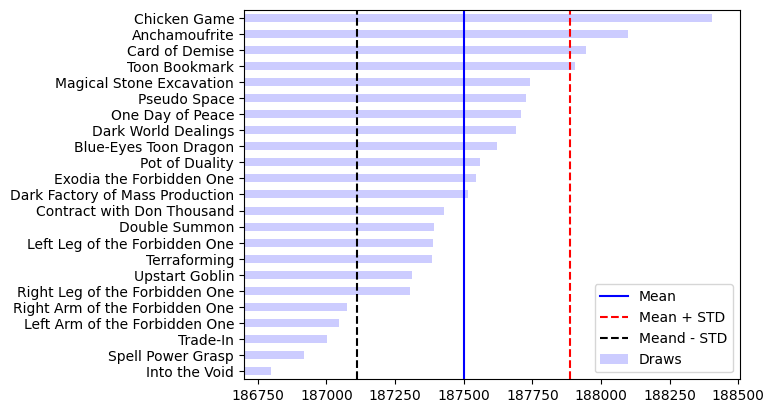

In [19]:
# Now, some charts of the data of the card at three copies


one_draw_series = one_copy.iloc[:, df.columns.get_loc("Draws")].to_list()
one_card_series = one_copy.iloc[:, df.columns.get_loc("Card")].to_list()

# Generate a new DF with selected data
three_df = pd.DataFrame(
    {
        "Draws": one_draw_series,
        "Cards": one_card_series
    },
    index=one_card_series,
).plot(kind="barh", alpha=0.2, color="blue")

# Set the limits of the x-axis
three_df.set_xlim(
    min(one_draw_series) - 100,
    max(one_draw_series) + 100
)

three_df.axvline(one_mean, color="blue", linestyle="-", label="Mean")
three_df.axvline(one_mean + one_std, color="red", linestyle="--", label="Mean + STD")
three_df.axvline(one_mean - one_std, color="black", linestyle="--", label="Meand - STD")

three_df.legend()

In [20]:
# Showing the results

print(f"Mean {one_mean} :: Median {one_median} :: STD {one_std}")

Mean 187500 :: Median 187514 :: STD 389


In [21]:
# Getting the info of the cards at 3 copies


three_copies = sorted_df.tail(5)
three_copies

,Card,Draws
4,Royal Magical Library,562022
7,Cursed Bamboo Sword,562231
17,Toon Table of Contents,562493
10,Magical Citadel of Endymion,562523
12,Golden Bamboo Sword,563160


In [22]:
# Getting the values of the draws

three_copies_values = three_copies.iloc[:, df.columns.get_loc("Draws")]

In [23]:
# Mean, Median and Standart Deviation of the three copies cards value

three_mean = int(three_copies_values.mean())
three_median = int(three_copies_values.median())
three_std = int(three_copies_values.std())

In [24]:
# Você pode notar que os valores de desvios entre as cartas que estão em uma copia e as cartas que estão em três são relativamente próximos
# embora as amostras sejam diferentes o alto número de jogos revela uma tendencia a uma constância nos valores.
# Com poucos jogos, algumas cartas que estão no deck não apareceriam, contudo, estamos simulando valores altos. Todas as cartas tendem a aparecer e os valores
# tendem a se 'equilibrar' dentro dos padrões.

# Porém, observem que essa diferença acaba ficando mais descrepante entre os cards que estão em uma cópia. Pois, em cada nova mão o máximo de valores que se podem comprar são um. 
# nesse caso, pode ser comprado um, dois ou até mesmo as três cópias desses cards em uma mão.
# Considerando um caso onde um jogador compre três copias de "Royal Magic Libary" ele tirou sobram somente duas opções para compra de todos os outros que podem ser representados por
# 37 * 36 / 2!. 

# You may notice that the deviation values between cards that have one copy and cards that have three copies are relatively close.
# Although the samples are different, the high number of games reveals a tendency toward consistency in the values.
# With only a few games, some cards in the deck would not appear. However, we are simulating a large number of games. All cards tend to appear, and the values
# tend to 'balance out' within the expected patterns.

# However, notice that this difference becomes more pronounced for cards that have only one copy in the deck. In each new hand, at most one copy of these cards can be drawn.
# In this case, one, two, or even all three copies of these cards can be drawn in a single hand.
# Considering a case where a player draws three copies of "Royal Magical Library", only two slots remain for drawing any of the other cards, which can be represented by
# 37 * 36 / 2!.

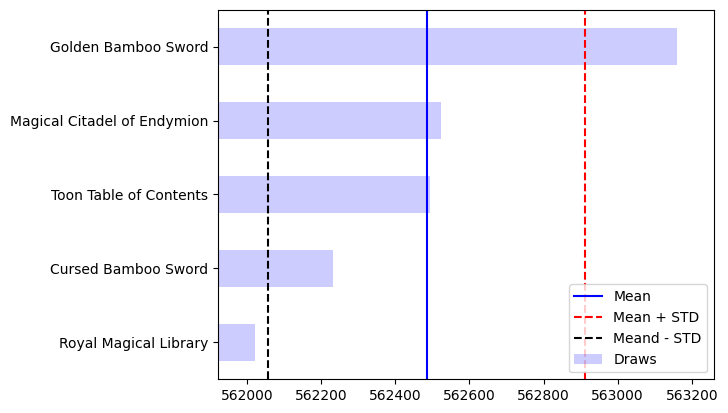

In [25]:
# Now, some charts of the data of the card at three copies


three_draw_series = three_copies.iloc[:, df.columns.get_loc("Draws")].to_list()
three_card_series = three_copies.iloc[:, df.columns.get_loc("Card")].to_list()

# Generate a new DF with selected data
three_df = pd.DataFrame(
    {
        "Draws": three_draw_series,
        "Cards": three_card_series
    },
    index=three_card_series,
).plot(kind="barh", alpha=0.2, color="blue")

# Set the limits of the x-axis
three_df.set_xlim(
    min(three_draw_series) - 100,
    max(three_draw_series) + 100
)

three_df.axvline(three_mean, color="blue", linestyle="-", label="Mean")
three_df.axvline(three_mean + three_std, color="red", linestyle="--", label="Mean + STD")
three_df.axvline(three_mean - three_std, color="black", linestyle="--", label="Meand - STD")

three_df.legend()
# plot = three_df.plot(kind="barh")

In [26]:
# Showing results

print(f"Mean {three_mean} :: Median {three_median} :: STD {three_std}")

Mean 562485 :: Median 562493 :: STD 428
